# makemore part 2: MLP

Following Karpathy's [makemore part 2](https://www.youtube.com/watch?v=TCH_1BHY58I), which implements
[Bengio et al. 2003](https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf), *A Neural Probabilistic Language Model*.

The bigram only looked at 1 previous character. Extending the count table to more context blows up fast
(27^4 ≈ 530k cells for 3 chars back, mostly zeros). The fix from the paper:
- give every character a small learned vector (**embedding**)
- feed the embeddings of the last few characters into a small neural net
- similar characters end up with similar embeddings, so the model can **generalize** to contexts it never saw

In [1]:
import random
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Data and vocabulary

In [2]:
words = open('data/names.txt', 'r').read().splitlines()
print(len(words), 'names')
words[:8]

32033 names


['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
chars = sorted(set(''.join(words)))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
vocab_size

27

## 2. Building the dataset

`block_size` = how many previous characters the model sees. For each name I slide a window of 3 chars,
padding the start with `.`. For `emma`:

```
... -> e
..e -> m
.em -> m
emm -> a
mma -> .
```

In [4]:
block_size = 3   # context length

def build_dataset(words):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]   # slide the window
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

Splitting into train / dev / test (80 / 10 / 10):
- **train**: fit the parameters
- **dev**: tune hyperparameters (embedding size, hidden size, lr...) and check for overfitting
- **test**: touch it only once at the very end

In [5]:
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


## 3. The network

```
3 chars -> lookup in C -> 3 embeddings (10 dims each)
        -> concatenate -> 30 numbers
        -> hidden layer (200 neurons) + tanh
        -> output layer -> 27 logits
        -> softmax -> probability of the next char
```

`C` is just another parameter, it gets trained with backprop like the weights.

In [6]:
n_embd = 10     # embedding size per char
n_hidden = 200  # neurons in the hidden layer

g = torch.Generator().manual_seed(2147483647)
C  = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((block_size * n_embd, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, vocab_size), generator=g)
b2 = torch.randn(vocab_size, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True

print('total parameters:', sum(p.nelement() for p in parameters))

total parameters: 11897


Quick look at the shapes for one minibatch, to make sure I understand what's going on:

In [7]:
ix = torch.randint(0, Xtr.shape[0], (32,), generator=g)
emb = C[Xtr[ix]]
print('emb      ', emb.shape)                     # (32, 3, 10)
print('flattened', emb.view(-1, block_size * n_embd).shape)  # (32, 30) -> concat of the 3 embeddings

emb       torch.Size([32, 3, 10])
flattened torch.Size([32, 30])


Notes:
- `emb.view(-1, 30)` concatenates the 3 embeddings without copying memory, it just reads the same storage as rows of 30
- `F.cross_entropy` does exp, normalize, pick the correct prob, -log, mean. Same as what I wrote by hand in part 1,
  but faster and numerically stable (doesn't blow up when a logit is large)

## 4. Finding a good learning rate

Instead of guessing, try learning rates from 0.001 to 1 (spaced exponentially) for 1000 steps, one lr per step,
and look at where the loss drops fastest before it gets unstable.

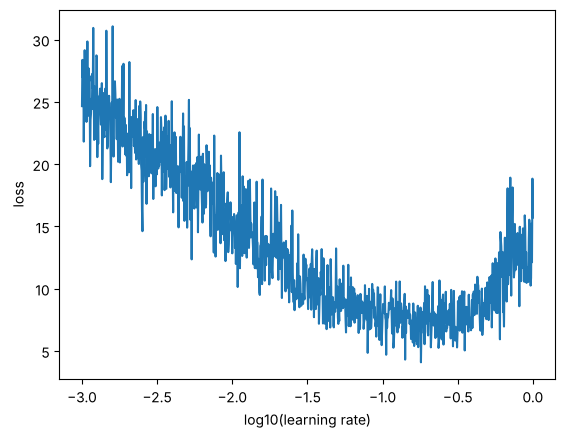

In [8]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10 ** lre

lri, lossi = [], []
for i in range(1000):
    ix = torch.randint(0, Xtr.shape[0], (32,), generator=g)
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    for p in parameters:
        p.grad = None
    loss.backward()

    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad

    lri.append(lre[i].item())
    lossi.append(loss.item())

plt.plot(lri, lossi)
plt.xlabel('log10(learning rate)')
plt.ylabel('loss');

The sweet spot is around 10^-1 = **0.1**. After that it gets noisy and unstable.

## 5. Training

Re-initializing so the lr search above doesn't affect the real run.
- **minibatches of 32**: each step uses a random 32 examples instead of all 180k. the gradient is noisier
  but each step is way faster, so I can do many more steps
- **learning rate decay**: 0.1 for the first half, then 0.01 to settle into the minimum

In [9]:
g = torch.Generator().manual_seed(2147483647)
C  = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((block_size * n_embd, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, vocab_size), generator=g)
b2 = torch.randn(vocab_size, generator=g)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

In [10]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)

    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    lossi.append(loss.log10().item())
    if i % 20000 == 0:
        print(f'step {i:6d} | loss {loss.item():.4f}')

step      0 | loss 27.8817


step  20000 | loss 2.5847


step  40000 | loss 2.0222


step  60000 | loss 2.3168


step  80000 | loss 2.2519


step 100000 | loss 2.0234


step 120000 | loss 1.9426


step 140000 | loss 2.3213


step 160000 | loss 2.2320


step 180000 | loss 2.0826


Plotting log10 of the loss because the first steps are much higher and would squash the rest of the plot.
The noise is from the minibatches. The drop at 100k is the lr decay kicking in.

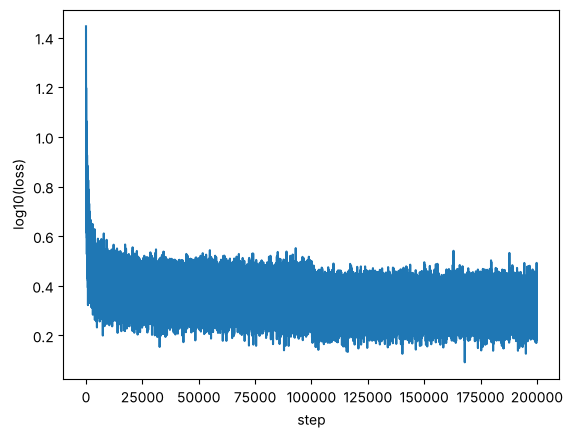

In [11]:
plt.plot(lossi)
plt.xlabel('step')
plt.ylabel('log10(loss)');

## 6. Evaluation

The loss printed during training is for one minibatch only, so it's noisy. Evaluating on the full splits instead.

In [12]:
@torch.no_grad()
def split_loss(split):
    X, Y = {'train': (Xtr, Ytr), 'dev': (Xdev, Ydev), 'test': (Xte, Yte)}[split]
    emb = C[X]
    h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1 + b1)
    logits = h @ W2 + b2
    return F.cross_entropy(logits, Y).item()

print(f"train: {split_loss('train'):.4f}")
print(f"dev:   {split_loss('dev'):.4f}")

train: 2.1276
dev:   2.1702


Train and dev are close, so the model isn't overfitting much. It's still a small model (~11k params)
for ~180k examples, so if anything it could be bigger.

Both are well below the bigram (2.45).

Now checking test once, at the end:

In [13]:
print(f"test:  {split_loss('test'):.4f}")

test:  2.1670


## 7. What did the embeddings learn?

`C` is 10-dimensional so I can't plot it directly. Plotting just the first 2 dimensions to get a rough idea.

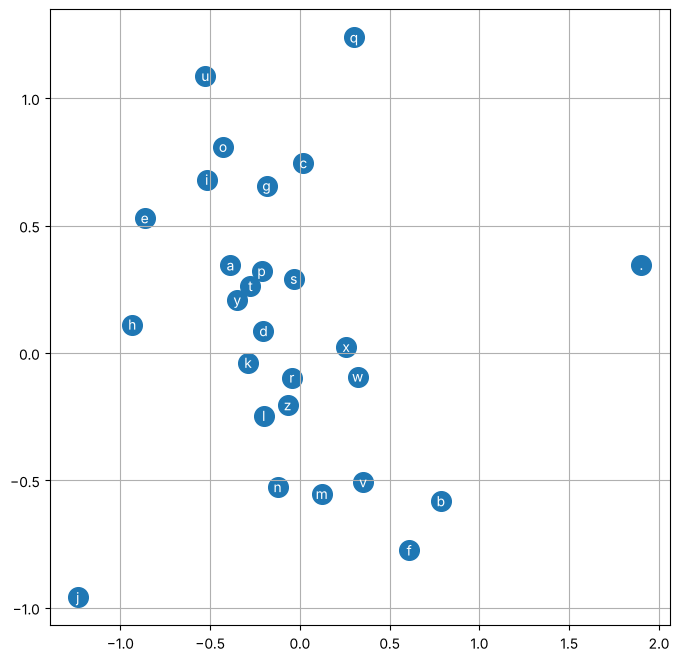

In [14]:
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i, 0].item(), C[i, 1].item(), itos[i], ha='center', va='center', color='white')
plt.grid('minor');

## 8. Sampling names

In [15]:
g = torch.Generator().manual_seed(2147483647 + 10)

with torch.no_grad():
    for _ in range(20):
        out = []
        context = [0] * block_size
        while True:
            emb = C[torch.tensor([context])]   # (1, block_size, n_embd)
            h = torch.tanh(emb.view(1, -1) @ W1 + b1)
            logits = h @ W2 + b2
            probs = F.softmax(logits, dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=g).item()
            context = context[1:] + [ix]
            out.append(ix)
            if ix == 0:
                break
        print(''.join(itos[i] for i in out))

carlah.
amille.
khirmy.
kheety.
skandane.
mahuen.
den.
art.
kaeli.
nellara.
chaiir.
kaleigh.
ham.
jorn.
quinn.
salin.
alianni.
wavero.
dearynix.
kaelissuri.


Way more name-like than the bigram output.

## Takeaways

- embeddings let the model share what it learns between similar characters, that's what beats the count table
- concatenation (not sum or average) keeps the **order** of the context characters
- minibatches: noisy gradient but many more cheap steps, worth it
- find the lr with a sweep instead of guessing, then decay it near the end
- always judge on **dev**, not on the minibatch loss and not on train. test only once at the end
- bug I had at first: `parameters = [C, W1, W2, b1, b1]`, so `b2` was never trained and `b1` got updated twice.
  dev loss was ~2.43 until I fixed it. always double check the parameters list